# Sky Weather - global AI model v3 (all cells of new HCMC)

LightGBM, self-supervised on Open-Meteo hourly history of the **67 grid cells** covering the 168 wards/communes of new HCMC.
Targets: temperature and rain (precipitation >= 0.1 mm) at t+1h / t+3h / t+6h.

* Training/evaluation code: `backend/scripts/train_global_v3.py`. This notebook reads its outputs; set `RETRAIN = True` to re-run it (~15 min).
* Features: the v2 `ai_model.build_features` (shared with serving) + static cell features `lat, lon, elevation, dist_to_coast_km, region one-hot`.
* Model files: `backend/models/v3/` (v2 files in `backend/models/` untouched).

In [1]:
import json, sqlite3, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display

BACKEND = Path.cwd().parent / 'backend'
sys.path.insert(0, str(BACKEND))
import ai_model
FIG = Path.cwd() / 'figures'; FIG.mkdir(exist_ok=True)
V3 = BACKEND / 'models' / 'v3'
DB_URI = f"file:{(BACKEND / 'data/history/cells_history.db').as_posix()}?mode=ro"
RETRAIN = False
np.random.seed(42)
pd.set_option('display.width', 160, 'display.precision', 3)
if RETRAIN or not (V3 / 'evaluation_v3.json').exists():
    subprocess.run([sys.executable, str(BACKEND / 'scripts' / 'train_global_v3.py')], check=True)
meta = json.loads((V3 / 'metadata_v3.json').read_text(encoding='utf-8'))
ev = json.loads((V3 / 'evaluation_v3.json').read_text(encoding='utf-8'))
static = json.loads((V3 / 'cell_static.json').read_text(encoding='utf-8'))
pc = pd.read_csv(V3 / 'per_cell_metrics.csv')
print(meta['model_version'], '| trained', meta['trained_at'])

lgbm-hcmc-global-v3-20261017 | trained 2026-10-17T13:06:19


## 1. Data audit (snapshot used for training)
The backfill is still running; the coverage below is what this model was trained on (recorded in `metadata_v3.json`).

In [2]:
snap = pd.DataFrame(meta['data_snapshot'], index=['first', 'last', 'rows']).T
snap['first'] = pd.to_datetime(snap['first']); snap['last'] = pd.to_datetime(snap['last'])
print('cells:', len(snap), '| rows with complete features:', int(snap.rows.sum()))
print(snap.groupby([snap['first'].dt.year.rename('first_year'), snap['last'].dt.strftime('%Y-%m').rename('last_month')]).size().rename('cells'))
con = sqlite3.connect(DB_URI, uri=True)
cols = ['temperature', 'humidity', 'precipitation', 'pressure_msl', 'wind_speed', 'cloud_cover']
q = 'SELECT ' + ', '.join(f'SUM({c} IS NULL) AS {c}_null, MIN({c}) AS {c}_min, MAX({c}) AS {c}_max' for c in cols) + ' FROM hourly'
aud = pd.read_sql(q, con).T[0]
print(pd.DataFrame({c: [aud[f'{c}_null'], aud[f'{c}_min'], aud[f'{c}_max']] for c in cols}, index=['nulls', 'min', 'max']))
dups = con.execute('SELECT COUNT(*) FROM (SELECT cell_id, timestamp FROM hourly GROUP BY 1, 2 HAVING COUNT(*) > 1)').fetchone()[0]
print('duplicate (cell, timestamp) rows:', dups)
con.close()

cells: 67 | rows with complete features: 2278046
first_year  last_month
2017        2026-10        1
2023        2026-10       66
Name: cells, dtype: int64


       temperature  humidity  precipitation  pressure_msl  wind_speed  cloud_cover
nulls          0.0       0.0            0.0           0.0         0.0          0.0
min           15.4      21.0            0.0         999.8         0.0          0.0
max           39.4     100.0           29.3        1019.5        67.8        100.0


duplicate (cell, timestamp) rows: 0


## 2. Static cell features
`dist_to_coast_km`: `data/history/coastline_raw` is empty, so the distance is the haversine distance to the nearest point of a **hand-digitised coastline polyline** (Can Gio - Vung Tau - Long Hai - Ho Tram - Binh Chau, plus a ring around Con Dao), accuracy a few km. Region = majority former province of the cell's wards (`locations.json`). lat/lon/elevation = the values the data was requested with (`cells` table).

                    cells  elev_min  elev_max  coast_min  coast_max  holdout
region                                                                      
Bà Rịa–Vũng Tàu cũ     22       2.0     162.0       2.29      32.82       22
Bình Dương cũ          23      10.0      81.0      62.11     124.35        7
TP.HCM cũ              22       4.0      25.3       5.48      84.47        2


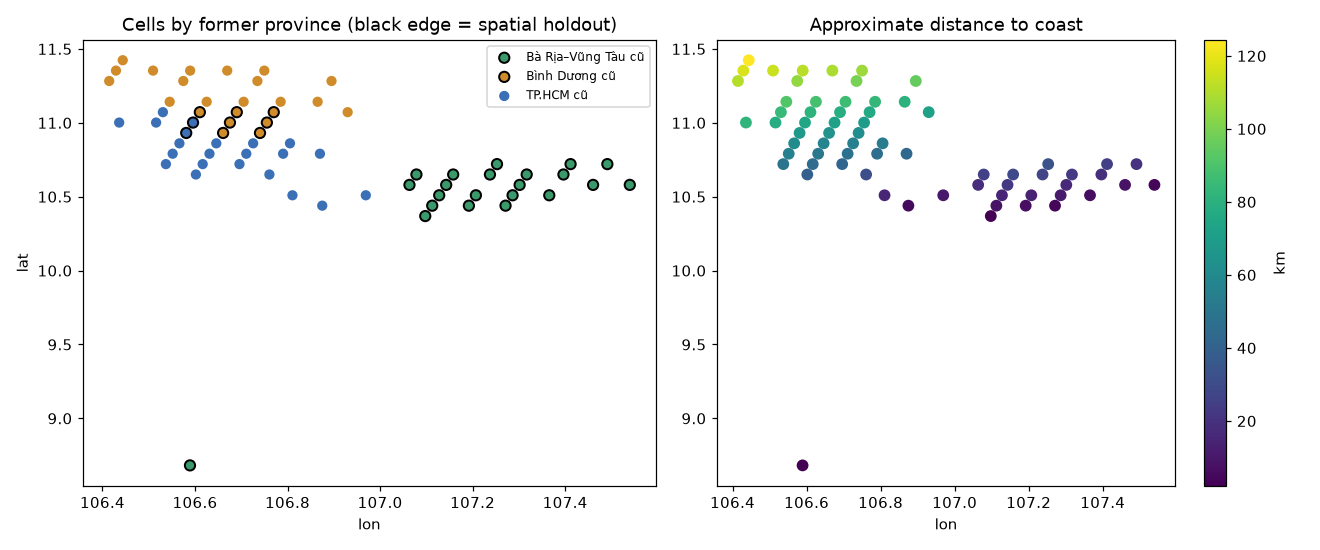

In [3]:
st = pd.DataFrame(static).T
for c in ['lat', 'lon', 'elevation', 'dist_to_coast_km']:
    st[c] = st[c].astype(float)
hold = set(meta['holdout_cells'])
st['holdout'] = st.index.isin(hold)
print(st.groupby('region').agg(cells=('lat', 'size'), elev_min=('elevation', 'min'), elev_max=('elevation', 'max'),
                               coast_min=('dist_to_coast_km', 'min'), coast_max=('dist_to_coast_km', 'max'), holdout=('holdout', 'sum')))
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
colors = {'TP.HCM cũ': '#3b6fb6', 'Bình Dương cũ': '#d08c2b', 'Bà Rịa–Vũng Tàu cũ': '#3a9a6b'}
for r, g in st.groupby('region'):
    ax[0].scatter(g.lon, g.lat, c=colors[r], label=r, s=45, edgecolors=['k' if h else 'none' for h in g.holdout], linewidths=1.3)
ax[0].set_title('Cells by former province (black edge = spatial holdout)'); ax[0].legend(fontsize=8)
ax[0].set_xlabel('lon'); ax[0].set_ylabel('lat')
s = ax[1].scatter(st.lon, st.lat, c=st.dist_to_coast_km, cmap='viridis', s=45); plt.colorbar(s, ax=ax[1], label='km')
ax[1].set_title('Approximate distance to coast'); ax[1].set_xlabel('lon')
plt.tight_layout(); plt.savefig(FIG / 'v3_cells.png', dpi=110); plt.close(); display(Image(FIG / 'v3_cells.png'))

## 3. Split
Chronological by issue time *t*; a row belongs to train/val only if *t+6h* is still inside the split, and there is a 7-day purge between splits.

* **train** up to 2024-06-30: 2023-01..2024-06 for all cells (+ 2017-2022 at tsn, the only cell with older data so far) - covers 1.5 rainy seasons.
* **val** 2024-07-08..2024-12-24: early stopping and rain decision thresholds (a full second half of the rainy season).
* **test** 2025-01-01 onward: all of 2025 for every cell (+ 2026 at tsn).

Why: 2023-2025 is the only window every cell has; a full calendar year of test covers both seasons.

In [4]:
sp = meta['split']
print(json.dumps(sp, indent=1))
print('test cells:', len(meta['test_cells']), '| cells evaluated on val window (no 2025 data):', len(meta['late_cells_evaluated_on_val_window']))
print('rain decision thresholds (val-tuned):', meta['rain_decision_threshold'])
print('best iterations:', meta['best_iterations'])

{
 "train_end": "2024-06-30 23:00:00",
 "val": [
  "2024-07-08 00:00:00",
  "2024-12-24 23:00:00"
 ],
 "test_start": "2025-01-01 00:00:00",
 "test_end": "2026-10-16 23:00:00",
 "purge": "7 days between splits; t and t+6h must lie inside a split",
 "rows": {
  "train": 930143,
  "val": 272958,
  "test": 1051629,
  "late_eval": 0
 }
}
test cells: 67 | cells evaluated on val window (no 2025 data): 0
rain decision thresholds (val-tuned): {'1h': 0.39, '3h': 0.33, '6h': 0.32}
best iterations: {'temp_1h': 449, 'rain_1h': 248, 'temp_3h': 1248, 'rain_3h': 286, 'temp_6h': 1156, 'rain_6h': 190}


## 4. Leakage checks
1. Future-perturbation: overwrite everything after *t* with noise and confirm features at *t* are unchanged.
2. Column audit: no target / forecast-product columns.
3. Split purge (asserted in the training script; re-checked from metadata).
4. Train/serve parity: `ai_model.predict_for_location` on raw 48-h windows from the DB reproduces the training-time predictions.

In [5]:
con = sqlite3.connect(DB_URI, uri=True)
rng = np.random.default_rng(42)
FEAT = ai_model.feature_columns_v3()
bad = n = 0
for cid in ['om-10.7909-106.6313', 'om-8.6819-106.5892', 'om-11.0018-106.6755']:
    df = pd.read_sql("SELECT * FROM hourly WHERE cell_id=? AND timestamp>='2025-03-01' AND timestamp<'2025-03-20' ORDER BY timestamp",
                     con, params=(cid,)).drop(columns='cell_id')
    f0 = ai_model.build_features_v3(df, static[cid])
    for i in rng.integers(60, len(df) - 12, 20):
        p = df.copy(); num = [c for c in p.columns if c != 'timestamp']
        p.loc[i + 1:, num] = rng.normal(size=(len(p) - i - 1, len(num))) * 100
        f1 = ai_model.build_features_v3(p, static[cid])
        bad += int(not np.allclose(f0.loc[i, FEAT].astype(float), f1.loc[i, FEAT].astype(float), equal_nan=True)); n += 1
print('feature rows changed by perturbing the future:', bad, '/', n)
forbidden = ['target', 'precipitation_probability', 'visibility', 'rain']
print('forbidden substrings in features:', [f for f in FEAT if any(s in f for s in forbidden) and f != 'is_rainy_season'])
print('train end + 6h < val start:', pd.Timestamp(sp['train_end']) < pd.Timestamp(sp['val'][0]),
      '| val end < test start:', pd.Timestamp(sp['val'][1]) < pd.Timestamp(sp['test_start']))
samples = json.loads((V3 / 'serving_samples.json').read_text())
diffs = []
ai_model.reset_v3_cache()
for s in samples:
    h = pd.read_sql('SELECT * FROM hourly WHERE cell_id=? AND timestamp<=? ORDER BY timestamp DESC LIMIT 48', con,
                    params=(s['cell_id'], s['issued_at'])).drop(columns='cell_id').iloc[::-1].reset_index(drop=True)
    out = ai_model.predict_for_location(h, s['cell_id'])
    for k in ('1h', '3h', '6h'):
        diffs += [abs(out['predictions'][k]['temperature'] - s['temp'][k]), abs(out['predictions'][k]['rain_probability'] - s['rain'][k])]
con.close()
print(f'serving vs training on {len(samples)} windows: max abs diff = {max(diffs):.4f} (serving rounds to 0.01 / 0.0001)')

feature rows changed by perturbing the future: 0 / 60
forbidden substrings in features: []
train end + 6h < val start: True | val end < test start: True


serving vs training on 15 windows: max abs diff = 0.0047 (serving rounds to 0.01 / 0.0001)


## 5. Results - all 67 cells, test period
Per-cell metrics, averaged over cells (each cell weighted equally). Baselines: **persistence** (value at *t*) and **climatology** (per cell, train-period mean by target month x hour; rain if frequency > 0.5).

In [6]:
full = pc[(pc.model == 'full') & (pc.split == 'test')]
agg = full.groupby('horizon')[['mae_v3', 'mae_persistence', 'mae_climatology', 'f1_v3', 'f1_persistence', 'f1_climatology', 'brier_v3']].mean()
print(agg.round(3))
w = full.assign(win_mae=full.mae_v3 < full[['mae_persistence', 'mae_climatology']].min(axis=1),
                win_f1=full.f1_v3 > full[['f1_persistence', 'f1_climatology']].max(axis=1))
print('\ncells where v3 beats BOTH baselines, per horizon (of', full.cell_id.nunique(), 'cells):')
print(w.groupby('horizon')[['win_mae', 'win_f1']].sum())
cells = {k: v for k, v in ev.items() if k != 'tsn'}
print(f"\nbeats_baselines (MAE and F1, all horizons): {sum(v['beats_baselines'] for v in cells.values())} / {len(cells)} cells")

         mae_v3  mae_persistence  mae_climatology  f1_v3  f1_persistence  f1_climatology  brier_v3
horizon                                                                                           
1h        0.344            0.691            1.024  0.685           0.668           0.384     0.084
3h        0.579            1.774            1.024  0.555           0.464           0.384     0.114
6h        0.699            3.046            1.024  0.513           0.347           0.384     0.121

cells where v3 beats BOTH baselines, per horizon (of 67 cells):
         win_mae  win_f1
horizon                 
1h            66      63
3h            66      67
6h            67      67

beats_baselines (MAE and F1, all horizons): 63 / 67 cells


### Where v3 does NOT beat a baseline

In [7]:
lose = w[~(w.win_mae & w.win_f1)].copy()
lose['f1_margin'] = lose.f1_v3 - lose[['f1_persistence', 'f1_climatology']].max(axis=1)
lose['mae_margin'] = lose[['mae_persistence', 'mae_climatology']].min(axis=1) - lose.mae_v3
lose['region'] = lose.cell_id.map(lambda c: static[c]['region'])
print(lose.groupby('horizon').size().rename('lost cell-horizons'))
print(lose[['cell_id', 'region', 'horizon', 'rain_rate', 'f1_v3', 'f1_persistence', 'f1_climatology', 'f1_margin', 'mae_margin']]
      .sort_values('f1_margin').round(3).to_string(index=False))

horizon
1h    4
3h    1
Name: lost cell-horizons, dtype: int64
            cell_id             region horizon  rain_rate  f1_v3  f1_persistence  f1_climatology  f1_margin  mae_margin
om-10.4394-106.8750          TP.HCM cũ      1h      0.178  0.642           0.645           0.389     -0.002       0.247
 om-8.6819-106.5892 Bà Rịa–Vũng Tàu cũ      1h      0.174  0.664           0.666           0.178     -0.001      -0.039
om-10.4394-107.1127 Bà Rịa–Vũng Tàu cũ      1h      0.192  0.669           0.670           0.321     -0.001       0.134
om-10.4394-107.1919 Bà Rịa–Vũng Tàu cũ      1h      0.179  0.648           0.649           0.351     -0.001       0.250
 om-8.6819-106.5892 Bà Rịa–Vũng Tàu cũ      3h      0.174  0.552           0.518           0.178      0.034      -0.010


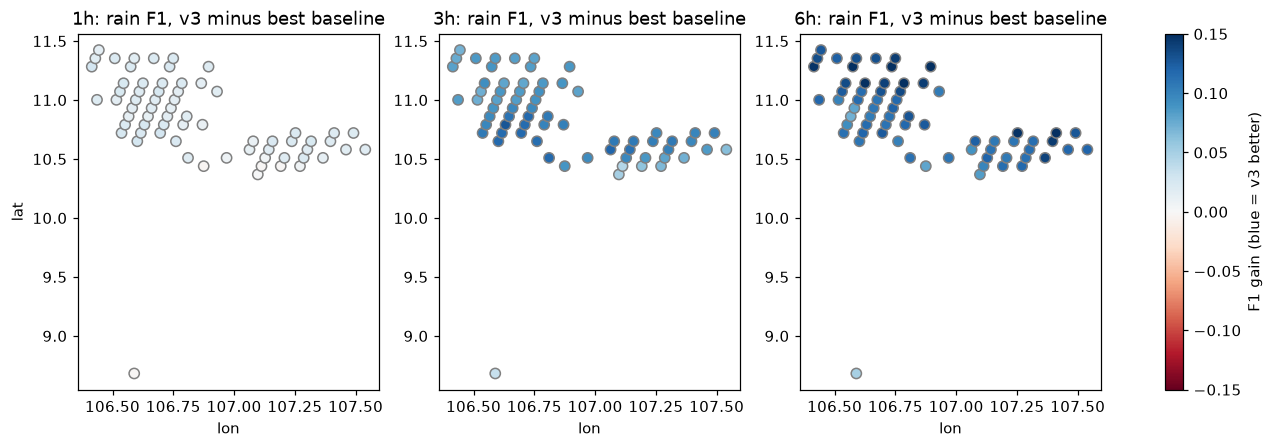

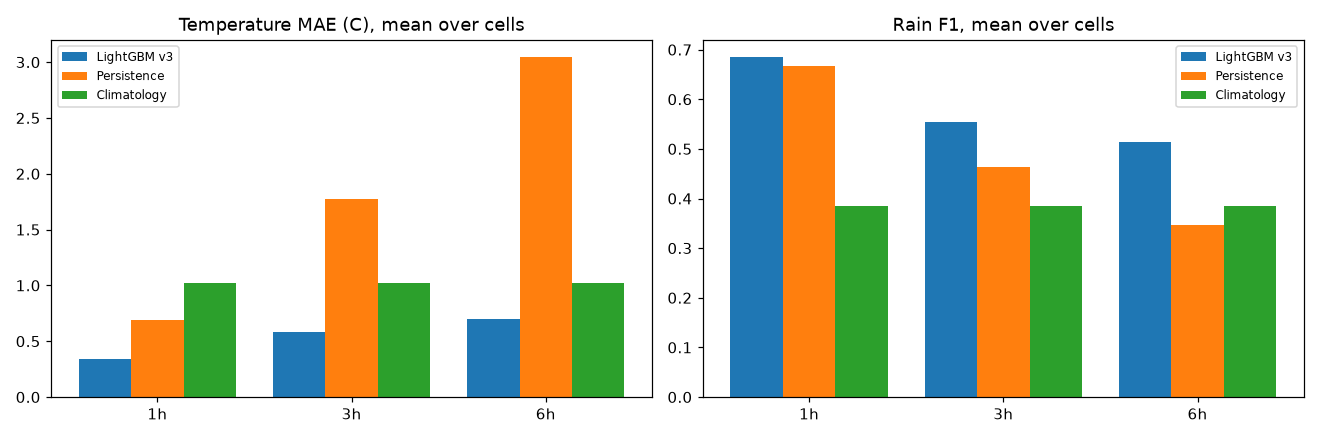

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for j, h in enumerate(['1h', '3h', '6h']):
    g = full[full.horizon == h].set_index('cell_id')
    gain = g.f1_v3 - g[['f1_persistence', 'f1_climatology']].max(axis=1)
    s = ax[j].scatter(st.loc[g.index, 'lon'], st.loc[g.index, 'lat'], c=gain, cmap='RdBu', vmin=-0.15, vmax=0.15, s=45, edgecolor='grey')
    ax[j].set_title(f'{h}: rain F1, v3 minus best baseline'); ax[j].set_xlabel('lon')
ax[0].set_ylabel('lat'); plt.colorbar(s, ax=ax, label='F1 gain (blue = v3 better)')
plt.savefig(FIG / 'v3_rain_f1_gain_map.png', dpi=110, bbox_inches='tight'); plt.close(); display(Image(FIG / 'v3_rain_f1_gain_map.png'))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(3); bw = 0.27
for k, (m, lab) in enumerate([('v3', 'LightGBM v3'), ('persistence', 'Persistence'), ('climatology', 'Climatology')]):
    ax[0].bar(x + (k - 1) * bw, agg[f'mae_{m}'], bw, label=lab); ax[1].bar(x + (k - 1) * bw, agg[f'f1_{m}'], bw, label=lab)
for a, t in zip(ax, ['Temperature MAE (C), mean over cells', 'Rain F1, mean over cells']):
    a.set_xticks(x); a.set_xticklabels(agg.index); a.set_title(t); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'v3_summary.png', dpi=110); plt.close(); display(Image(FIG / 'v3_summary.png'))

## 6. Spatial holdout
A second model is trained **without** every former BR-VT cell (incl. Con Dao) and the ring of cells around Thu Dau Mot, and evaluated on those cells over the same test window. It is compared with the full model (which saw those cells) and the baselines. The climatology baseline still uses each cell's own train-period history (a per-cell statistic, not something the model learned).

In [9]:
hm = pc[(pc.model == 'holdout') & pc.holdout_cell]
fm = pc[(pc.model == 'full') & pc.holdout_cell & (pc.split == 'test')]
tab = pd.DataFrame({'mae_holdout_model': hm.groupby('horizon').mae_v3.mean(), 'mae_full_model': fm.groupby('horizon').mae_v3.mean(),
                    'mae_persistence': hm.groupby('horizon').mae_persistence.mean(), 'mae_climatology': hm.groupby('horizon').mae_climatology.mean(),
                    'f1_holdout_model': hm.groupby('horizon').f1_v3.mean(), 'f1_full_model': fm.groupby('horizon').f1_v3.mean(),
                    'f1_persistence': hm.groupby('horizon').f1_persistence.mean(), 'f1_climatology': hm.groupby('horizon').f1_climatology.mean()})
print('holdout cells:', hm.cell_id.nunique()); print(tab.round(3))
hb = {k: v['holdout_model']['beats_baselines'] for k, v in ev.items() if k != 'tsn' and 'holdout_model' in v}
print(f'holdout model beats both baselines on all metrics at {sum(hb.values())} / {len(hb)} holdout cells')
hm2 = hm.assign(region=hm.cell_id.map(lambda c: static[c]['region']))
print(hm2.groupby(['region', 'horizon'])[['mae_v3', 'mae_persistence', 'mae_climatology', 'f1_v3', 'f1_persistence', 'f1_climatology']].mean().round(3))
cd = hm[hm.cell_id == 'om-8.6819-106.5892']
print('\nCon Dao (holdout model):')
print(cd[['horizon', 'mae_v3', 'mae_persistence', 'mae_climatology', 'f1_v3', 'f1_persistence', 'f1_climatology']].round(3).to_string(index=False))

holdout cells: 31
         mae_holdout_model  mae_full_model  mae_persistence  mae_climatology  f1_holdout_model  f1_full_model  f1_persistence  f1_climatology
horizon                                                                                                                                      
1h                   0.355           0.335            0.660            0.969             0.666          0.679           0.664           0.374
3h                   0.615           0.562            1.674            0.969             0.537          0.549           0.462           0.374
6h                   0.751           0.675            2.860            0.969             0.489          0.505           0.342           0.374
holdout model beats both baselines on all metrics at 23 / 31 holdout cells
                            mae_v3  mae_persistence  mae_climatology  f1_v3  f1_persistence  f1_climatology
region             horizon                                                               

## 7. tsn: v2 (single point) vs v3 (global)
Same rows: test-period issue hours of cell om-10.7909-106.6313 (= tsn), 2025-01-01 onward incl. 2026. Each model uses its own val-tuned rain threshold. Caveat: v2 used 2024 as validation, 2017-2023 as train; v3 used 2017-2024-06 (tsn) as train - both never saw 2025+.

In [10]:
v = pd.DataFrame(meta['tsn_v2_vs_v3']).pivot(index='horizon', columns='model', values=['mae', 'f1'])
print(v.round(3))
t = ev['tsn']; print('\ntsn test period:', t['test_period'], '| beats_baselines:', t['beats_baselines'])
print(pd.DataFrame({h: [t[f'temperature_mae_{h}'], t[f'baseline_persistence_mae_{h}'], t[f'baseline_climatology_mae_{h}'],
                        t[f'rain_f1_{h}'], t[f'baseline_persistence_f1_{h}'], t[f'baseline_climatology_f1_{h}']] for h in ['1h', '3h', '6h']},
                   index=['MAE v3', 'MAE persistence', 'MAE climatology', 'F1 v3', 'F1 persistence', 'F1 climatology']))

           mae            f1       
model       v2     v3     v2     v3
horizon                            
1h       0.379  0.360  0.653  0.670
3h       0.647  0.623  0.535  0.552
6h       0.791  0.753  0.525  0.514

tsn test period: 2025-01-01..2026-10-16 | beats_baselines: True
                    1h     3h     6h
MAE v3           0.360  0.623  0.753
MAE persistence  0.757  1.971  3.387
MAE climatology  1.089  1.089  1.089
F1 v3            0.670  0.552  0.514
F1 persistence   0.645  0.423  0.322
F1 climatology   0.398  0.398  0.398


static feature share of gain (temp 6h): {'lat': 0.0047, 'lon': 0.0013, 'elevation': 0.001, 'dist_to_coast_km': 0.0106, 'region_hcm': 0.0001, 'region_bd': 0.0, 'region_brvt': 0.0001}


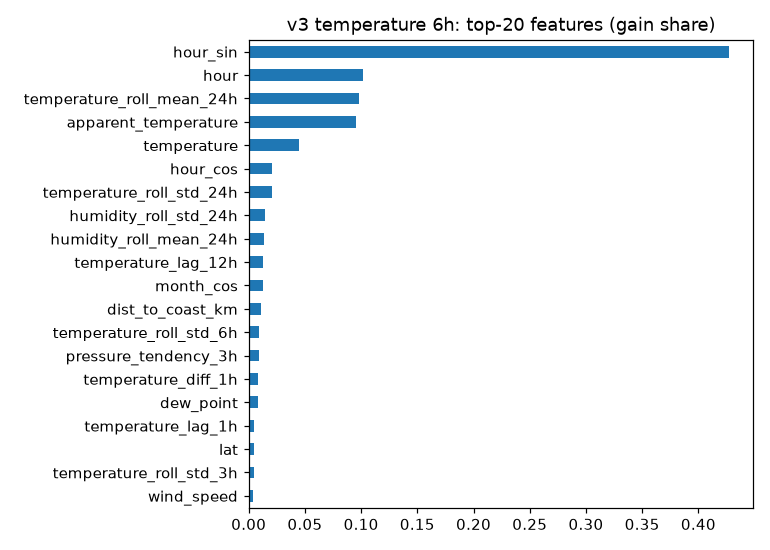

In [11]:
assert ai_model._load_v3()
imp = pd.Series(ai_model._v3['models']['temp_6h'].feature_importance('gain'), index=ai_model.feature_columns_v3())
imp = (imp / imp.sum()).sort_values(ascending=False)
print('static feature share of gain (temp 6h):', imp[ai_model.STATIC_FEATURES].round(4).to_dict())
fig, ax = plt.subplots(figsize=(7, 5)); imp.head(20)[::-1].plot.barh(ax=ax); ax.set_title('v3 temperature 6h: top-20 features (gain share)')
plt.tight_layout(); plt.savefig(FIG / 'v3_feature_importance.png', dpi=110); plt.close(); display(Image(FIG / 'v3_feature_importance.png'))

## 8. Limitations
* Data is Open-Meteo **model** output (historical forecast API), not station observations: skill means predicting the next hours of that gridded series.
* Cells other than tsn only have 2023-2025 so far; training covers 18 months for them. Re-run `python scripts/train_global_v3.py` (then this notebook) when the backfill adds 2017-2022; split dates are fixed so results stay comparable.
* Distance to coast comes from a hand-digitised polyline (few-km accuracy).
* One rain decision threshold per horizon for all cells (tuned on val), not per cell.
* The served model is the full model; section 6 estimates how it generalises to an area it has never seen.